# Dummy Catastrophe Model, UK Flood Risk — Notebook 01: Exploratory Data Analysis

**Objective:** Inspect the synthetic property portfolio, check data quality, and understand how insured values and illustrative flood risk are distributed.

This is a learning dataset. The properties, coordinates, flood probabilities and depths are synthetic. They are not verified real-world property or flood-risk data.

**Learning outcomes**
- Load and inspect a CSV with pandas.
- Check identifiers, missing values, ranges and duplicates.
- Summarise exposure by region, property type and flood zone.
- Create clear charts and explain what they do (and do not) tell us.


## 1. Import the libraries

In [28]:
%pip install pandas numpy matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display a sensible number of rows and columns in notebook outputs
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("Libraries loaded successfully.")

Note: you may need to restart the kernel to use updated packages.
Libraries loaded successfully.


## 2. Load the portfolio

Read the csv as a data frame.

In [29]:
file_path = "synthetic_uk_flood_portfolio_1000_geocoded.csv"
df = pd.read_csv(file_path)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

df.head()

Rows: 1,000
Columns: 15


,property_id,region,area,latitude,longitude,property_type,year_built,building_sum_insured_gbp,contents_sum_insured_gbp,total_sum_insured_gbp,deductible_gbp,policy_limit_gbp,illustrative_flood_zone,annual_flood_probability,baseline_flood_depth_m
0,P0001,East Anglia,Cambridge,52.153,0.106,Terraced,1932,147000,25000,172000,7500,185000,Medium,0.015,0.182
1,P0002,East Anglia,Cambridge,52.236,0.167,Commercial,1929,460000,59000,519000,7500,460000,Low,0.006,0.082
2,P0003,Yorkshire,York,53.923,-1.084,Flat,1981,170000,34000,204000,7500,175000,High,0.040,0.442
3,P0004,Thames Valley,Reading,51.454,-0.971,Commercial,1913,553000,69000,622000,5000,610000,Low,0.004,0.115
4,P0005,Severn Basin,Gloucester,51.877,-2.270,Semi-detached,1965,176000,50000,226000,5000,195000,High,0.040,0.456


## 3. Understand the structure

Check the columns and get some summary statistics of numeric columns

In [30]:
# Column names and data types
df.info()

# A quick statistical summary of numeric columns
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   property_id               1000 non-null   str    
 1   region                    1000 non-null   str    
 2   area                      1000 non-null   str    
 3   latitude                  1000 non-null   float64
 4   longitude                 1000 non-null   float64
 5   property_type             1000 non-null   str    
 6   year_built                1000 non-null   int64  
 7   building_sum_insured_gbp  1000 non-null   int64  
 8   contents_sum_insured_gbp  1000 non-null   int64  
 9   total_sum_insured_gbp     1000 non-null   int64  
 10  deductible_gbp            1000 non-null   int64  
 11  policy_limit_gbp          1000 non-null   int64  
 12  illustrative_flood_zone   1000 non-null   str    
 13  annual_flood_probability  1000 non-null   float64
 14  baseline_flood_depth

,count,mean,std,min,25%,50%,75%,max
latitude,"1,000.000",52.522,0.890,51.382,51.831,52.211,53.772,54.016
longitude,"1,000.000",-0.914,1.175,-2.328,-1.617,-1.118,0.056,1.406
year_built,"1,000.000","1,961.553",35.950,"1,900.000","1,932.000","1,960.500","1,993.000","2,025.000"
building_sum_insured_gbp,"1,000.000","282,541.000","151,255.316","70,000.000","177,000.000","245,000.000","345,250.000","1,058,000.000"
contents_sum_insured_gbp,"1,000.000","63,302.000","33,707.818","14,000.000","39,000.000","55,500.000","80,000.000","250,000.000"
total_sum_insured_gbp,"1,000.000","345,843.000","175,889.208","85,000.000","217,000.000","305,500.000","427,250.000","1,186,000.000"
deductible_gbp,"1,000.000","5,710.000","2,082.724","2,500.000","5,000.000","5,000.000","7,500.000","10,000.000"
policy_limit_gbp,"1,000.000","347,125.000","180,381.115","100,000.000","215,000.000","300,000.000","430,000.000","1,345,000.000"
annual_flood_probability,"1,000.000",0.014,0.009,0.002,0.007,0.013,0.019,0.044
baseline_flood_depth_m,"1,000.000",0.215,0.223,0.030,0.067,0.143,0.286,1.691


**My observations**

- All monetary values have recorded as integers. 
- Lat/long, annual_flood_probability, and baseline_flood_depth_m are also numeric as floats.
- Min insured values seem high! Without a proper portfolio is hard to verify. Although no zero/negative values.

## 4. Data-quality checks

In [31]:
# Missing values by column
missing = df.isna().sum().sort_values(ascending=False)
display(missing.to_frame("missing_values"))

# Duplicate property IDs
duplicate_ids = df["property_id"].duplicated().sum()

# Duplicate complete rows
duplicate_rows = df.duplicated().sum()

print(f"Duplicate property IDs: {duplicate_ids}")
print(f"Duplicate complete rows: {duplicate_rows}")

,missing_values
property_id,0
region,0
area,0
latitude,0
longitude,0
property_type,0
year_built,0
building_sum_insured_gbp,0
contents_sum_insured_gbp,0
total_sum_insured_gbp,0


Duplicate property IDs: 0
Duplicate complete rows: 0


### Check key business rules

- Each property should have a unique ID.
- Total sum insured should equal building plus contents sum insured.
- Annual flood probabilities should be between 0 and 1.
- Latitude should be between -90 and 90; longitude between -180 and 180.
- Policy limits and deductibles should not be negative.

A check returning `True` means the rule passed for the whole dataset.

In [32]:
checks = {
    "Property IDs are unique": df["property_id"].is_unique,
    "Total sum insured reconciles": (
        df["total_sum_insured_gbp"]
        == df["building_sum_insured_gbp"] + df["contents_sum_insured_gbp"]
    ).all(),
    "Flood probabilities are between 0 and 1": (
        df["annual_flood_probability"].between(0, 1)
    ).all(),
    "Latitude is valid": df["latitude"].between(-90, 90).all(),
    "Longitude is valid": df["longitude"].between(-180, 180).all(),
    "Deductibles are non-negative": (df["deductible_gbp"] >= 0).all(),
    "Policy limits are non-negative": (df["policy_limit_gbp"] >= 0).all(),
}

for check, passed in checks.items():
    print(f'{"PASS" if passed else "FAIL"} — {check}')

PASS — Property IDs are unique
PASS — Total sum insured reconciles
PASS — Flood probabilities are between 0 and 1
PASS — Latitude is valid
PASS — Longitude is valid
PASS — Deductibles are non-negative
PASS — Policy limits are non-negative


**Important:** valid latitude/longitude ranges only prove that coordinates are numerically valid. They do not prove that a point is on land, in the named town, or at a real property address.

## 5. Portfolio overview

In [33]:
total_tiv = df["total_sum_insured_gbp"].sum()
mean_tiv = df["total_sum_insured_gbp"].mean()
median_tiv = df["total_sum_insured_gbp"].median()

print(f"Number of properties: {len(df):,}")
print(f"Total sum insured: £{total_tiv:,.0f}")
print(f"Mean sum insured per property: £{mean_tiv:,.0f}")
print(f"Median sum insured per property: £{median_tiv:,.0f}")
print(f"Mean annual flood probability: {df['annual_flood_probability'].mean():.2%}")
print(f"Median annual flood probability: {df['annual_flood_probability'].median():.2%}")

Number of properties: 1,000
Total sum insured: £345,843,000
Mean sum insured per property: £345,843
Median sum insured per property: £305,500
Mean annual flood probability: 1.41%
Median annual flood probability: 1.25%


## 6. Exposure by region

Total sum insured (often abbreviated to TSI or TIV, depending on context) is a measure of the portfolio's insured value. It is **not** the same as expected loss: it does not account for hazard probability, damage severity or policy terms.

In [34]:
region_summary = (
    df.groupby("region")
      .agg(
          property_count=("property_id", "count"),
          total_sum_insured_gbp=("total_sum_insured_gbp", "sum"),
          average_sum_insured_gbp=("total_sum_insured_gbp", "mean"),
          mean_flood_probability=("annual_flood_probability", "mean")
      )
      .sort_values("total_sum_insured_gbp", ascending=False)
)

display(region_summary.style.format({
    "total_sum_insured_gbp": "£{:,.0f}",
    "average_sum_insured_gbp": "£{:,.0f}",
    "mean_flood_probability": "{:.2%}"
}))

,property_count,total_sum_insured_gbp,average_sum_insured_gbp,mean_flood_probability
region,,,,
Yorkshire,262,"£91,186,000","£348,038",1.42%
East Anglia,260,"£90,373,000","£347,588",1.20%
Severn Basin,243,"£85,630,000","£352,387",1.74%
Thames Valley,235,"£78,654,000","£334,698",1.31%


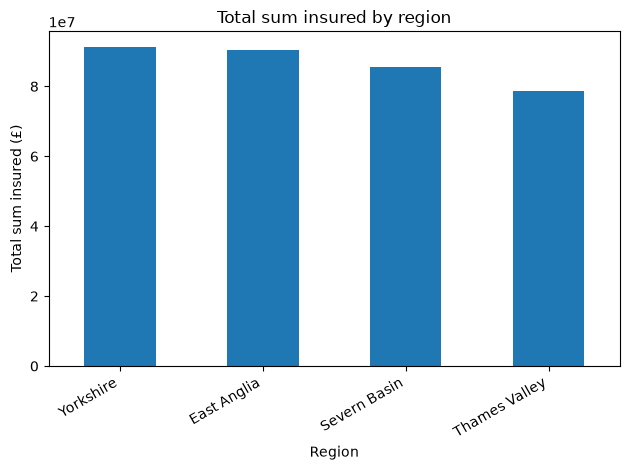

In [35]:
region_summary["total_sum_insured_gbp"].plot(kind="bar")
plt.title("Total sum insured by region")
plt.xlabel("Region")
plt.ylabel("Total sum insured (£)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Interpretation

The portfolio is relatively evenly distributed financially, although the risk characteristics differ. This is the more significant source of difference between the regions. It is therefore worth investigating the Severn Basin first.

## 7. Exposure by property type

In [36]:
type_summary = (
    df.groupby("property_type")
      .agg(
          property_count=("property_id", "count"),
          total_sum_insured_gbp=("total_sum_insured_gbp", "sum"),
          average_sum_insured_gbp=("total_sum_insured_gbp", "mean"),
          median_sum_insured_gbp=("total_sum_insured_gbp", "median")
      )
      .sort_values("average_sum_insured_gbp", ascending=False)
)

display(type_summary.style.format({
    "total_sum_insured_gbp": "£{:,.0f}",
    "average_sum_insured_gbp": "£{:,.0f}",
    "median_sum_insured_gbp": "£{:,.0f}"
}))

,property_count,total_sum_insured_gbp,average_sum_insured_gbp,median_sum_insured_gbp
property_type,,,,
Commercial,110,"£69,409,000","£630,991","£617,000"
Detached,273,"£115,703,000","£423,821","£402,000"
Semi-detached,267,"£81,044,000","£303,536","£290,000"
Terraced,198,"£48,183,000","£243,348","£220,500"
Flat,152,"£31,504,000","£207,263","£197,000"


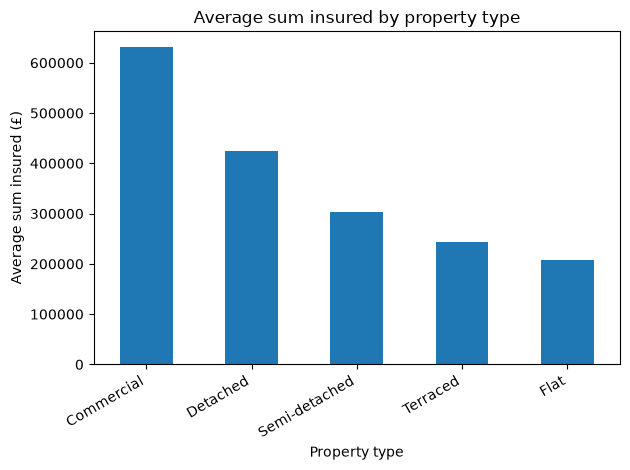

In [37]:
type_summary["average_sum_insured_gbp"].plot(kind="bar")
plt.title("Average sum insured by property type")
plt.xlabel("Property type")
plt.ylabel("Average sum insured (£)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 8. Compare illustrative flood zones

In [38]:
zone_order = ["Low", "Medium", "High"]

zone_summary = (
    df.groupby("illustrative_flood_zone")
      .agg(
          property_count=("property_id", "count"),
          total_sum_insured_gbp=("total_sum_insured_gbp", "sum"),
          average_flood_probability=("annual_flood_probability", "mean"),
          average_baseline_depth_m=("baseline_flood_depth_m", "mean")
      )
      .reindex(zone_order)
)

display(zone_summary.style.format({
    "total_sum_insured_gbp": "£{:,.0f}",
    "average_flood_probability": "{:.2%}",
    "average_baseline_depth_m": "{:.2f} m"
}))

,property_count,total_sum_insured_gbp,average_flood_probability,average_baseline_depth_m
illustrative_flood_zone,,,,
Low,447,"£157,696,000",0.67%,0.10 m
Medium,403,"£136,620,000",1.63%,0.25 m
High,150,"£51,527,000",3.05%,0.48 m


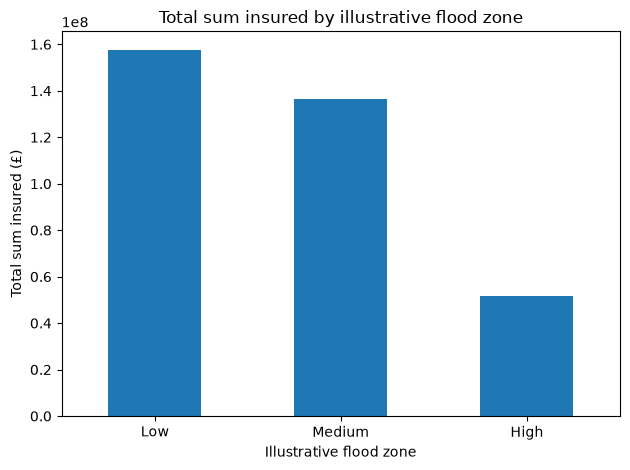

In [39]:
zone_summary["total_sum_insured_gbp"].plot(kind="bar")
plt.title("Total sum insured by illustrative flood zone")
plt.xlabel("Illustrative flood zone")
plt.ylabel("Total sum insured (£)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Spatial scatter plot

This first spatial view uses longitude and latitude as a simple scatter plot. Each point represents one synthetic property. The colours show the illustrative flood-zone classification.

This is not a map: there is no coastline, road network or flood outline. It is a quick way to check whether the generated coordinates form geographic clusters.

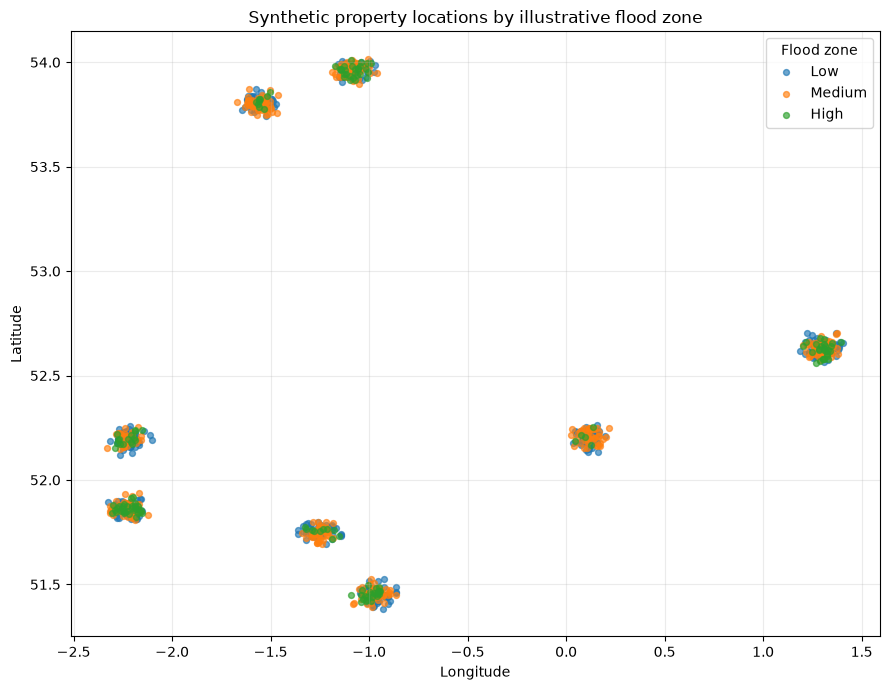

In [40]:
zone_colors = {"Low": "tab:green", "Medium": "tab:orange", "High": "tab:red"}

fig, ax = plt.subplots(figsize=(9, 7))

for zone in zone_order:
    subset = df[df["illustrative_flood_zone"] == zone]
    ax.scatter(
        subset["longitude"],
        subset["latitude"],
        label=zone,
        alpha=0.65,
        s=18
    )

ax.set_title("Synthetic property locations by illustrative flood zone")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(title="Flood zone")
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

Now I want to experiment with adding a coastline to the scatter graph to get a simplified map of insurance property.

Note: you may need to restart the kernel to use updated packages.


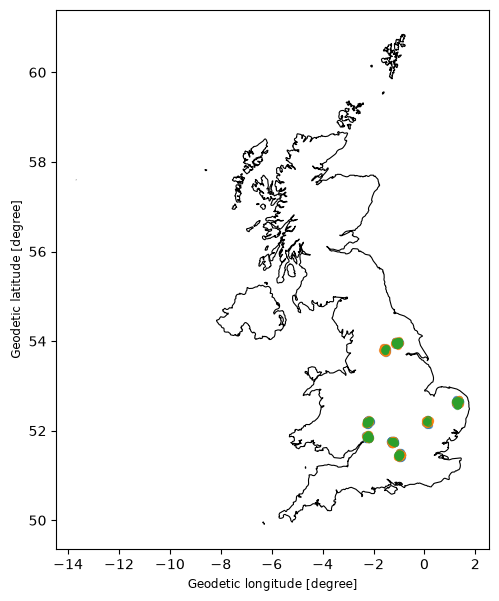

In [41]:
%pip install geopandas

import geopandas as gpd

# Natural Earth country boundaries (downloaded once, then read from the URL)
url = "https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_0_countries.zip"
world = gpd.read_file(url)
uk = world[world["ADMIN"] == "United Kingdom"]

fig, ax = plt.subplots(figsize=(9, 7))

# Coastline first, so the points sit on top
uk.boundary.plot(ax=ax, color="black", linewidth=0.8, zorder=1)

for zone in zone_order:
    subset = df[df["illustrative_flood_zone"] == zone]
    ax.scatter(
        subset["longitude"], subset["latitude"],
        label=zone, alpha=0.65, s=18, zorder=2,
    )

Epic! That worked better than expected. Now to zoom and improve visual.

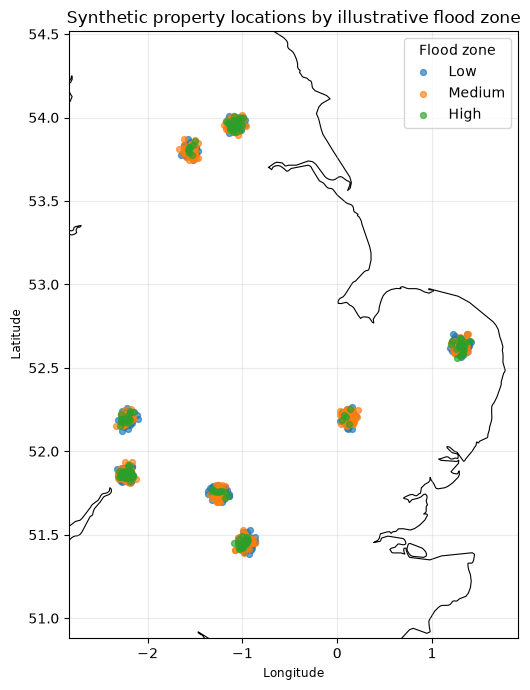

In [42]:
fig, ax = plt.subplots(figsize=(9, 7))

uk.boundary.plot(ax=ax, color="black", linewidth=0.8, zorder=1)

for zone in zone_order:
    subset = df[df["illustrative_flood_zone"] == zone]
    ax.scatter(
        subset["longitude"], subset["latitude"],
        label=zone, alpha=0.65, s=18, zorder=2,
    )

# Zoom to your data, otherwise the whole UK (up to Shetland) is shown
pad = 0.5
ax.set_xlim(df["longitude"].min() - pad, df["longitude"].max() + pad)
ax.set_ylim(df["latitude"].min() - pad, df["latitude"].max() + pad)

ax.set_title("Synthetic property locations by illustrative flood zone")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(title="Flood zone")
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

## 10. My mini-analysis

Highest exposure is in the Severn Basin, but sums insured are consistent across all of the regions.
Detatched housing is the largest asset group both in terms of insured sum and number of properties.
Flood zone concentration is also greatest in Severn Basin, though it worth highlighting the concentration in northern East Anglia and around York.

Limitations: 
Geospatial data lacks appropriate resolution (key to this is the fact it is fake!), we would not expect blobs of exposure like this.
We would need to pair this with historic data in a realistic scenario.
We also lack any information on preventative measures against flood risk.

## 11. What comes next?

In Notebook 02, I will build the first simplified loss calculation:
1. Convert flood depth into a damage ratio using an explicitly defined vulnerability function.
2. Calculate gross damage at property level.
3. Apply deductibles and policy limits.
4. Compare gross damage with insurer-paid loss.

Only after validating that calculation will we introduce event simulation and annual loss distributions.